In [1]:
!pip install tensorflow matplotlib pillow

In [3]:
import tensorflow as tf
import os

url = "https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip"

zip_path = tf.keras.utils.get_file(
    "cats_and_dogs_filtered.zip",
    origin=url,
    extract=True
)

dataset_path = os.path.join(
    os.path.dirname(zip_path),
    "cats_and_dogs_filtered"
)

train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "validation")

print("Dataset downloaded successfully!")
print("Training folder:", train_path)
print("Validation folder:", val_path)

68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Dataset downloaded successfully!
Training folder: /root/.keras/datasets/cats_and_dogs_filtered/train
Validation folder: /root/.keras/datasets/cats_and_dogs_filtered/validation


In [5]:
import os

print("Dataset folder:", dataset_path)
print("Folder exists:", os.path.exists(dataset_path))

print("\nKeras datasets:")
print(os.listdir("/root/.keras/datasets"))

Dataset folder: /root/.keras/datasets/cats_and_dogs_filtered
Folder exists: False

Keras datasets:
['cats_and_dogs_filtered_extracted', 'cats_and_dogs_filtered.zip']


In [6]:
import os
import tensorflow as tf

dataset_path = "/root/.keras/datasets/cats_and_dogs_filtered_extracted"

print(os.listdir(dataset_path))

['cats_and_dogs_filtered']


In [7]:
dataset_path = "/root/.keras/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered"

train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "validation")

print("Train exists:", os.path.exists(train_path))
print("Validation exists:", os.path.exists(val_path))

Train exists: True
Validation exists: True


In [8]:
img_size = (128, 128)
batch_size = 32

train_data = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="binary"
)

print("Classes:", train_data.class_names)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']


In [9]:
import os

base_path = "/root/.keras/datasets/cats_and_dogs_filtered_extracted"

for root, dirs, files in os.walk(base_path):
    if "train" in dirs and "validation" in dirs:
        dataset_path = root
        break

print("Dataset path:", dataset_path)

train_path = os.path.join(dataset_path, "train")
val_path = os.path.join(dataset_path, "validation")

print("Train folder exists:", os.path.exists(train_path))
print("Validation folder exists:", os.path.exists(val_path))

Dataset path: /root/.keras/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered
Train folder exists: True
Validation folder exists: True


In [10]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Input image
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1.0 / 255),

    # Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [12]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.5170 - loss: 0.6972 - val_accuracy: 0.5990 - val_loss: 0.6834
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.6020 - loss: 0.6655 - val_accuracy: 0.6540 - val_loss: 0.6164
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.6670 - loss: 0.6077 - val_accuracy: 0.6090 - val_loss: 0.6416
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.7150 - loss: 0.5559 - val_accuracy: 0.7020 - val_loss: 0.5841
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.7345 - loss: 0.5379 - val_accuracy: 0.7020 - val_loss: 0.5645
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.7800 - loss: 0.4647 - val_accuracy: 0.7190 - val_loss: 0.5610
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.8070 - loss: 0.4248 - val_accuracy: 0.7170 - val_loss: 0.5812
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.8370 - loss: 0.3600 - val_accuracy: 0.7120 - val_loss:

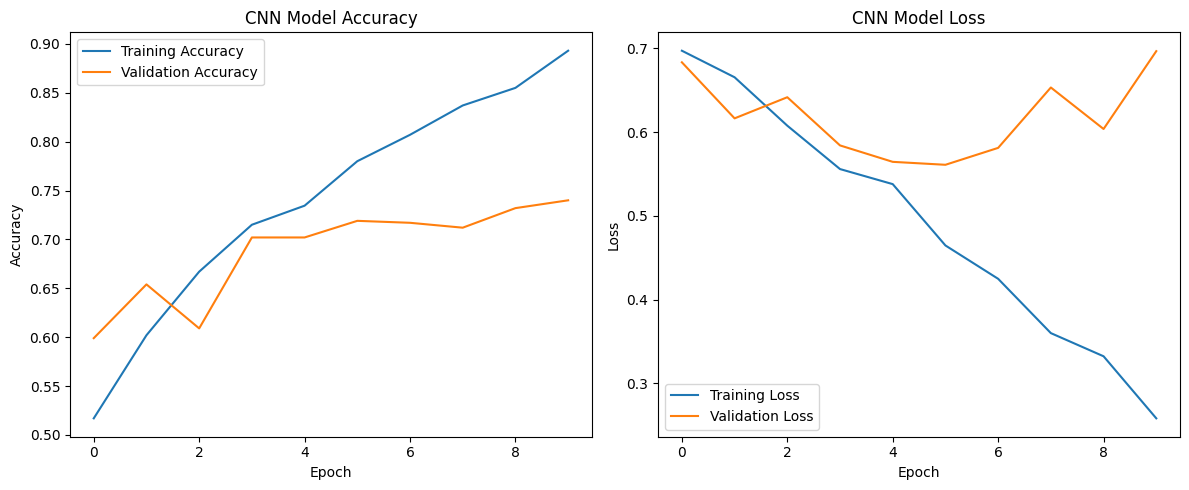

In [13]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [14]:
loss, accuracy = model.evaluate(val_data)

print("Final Model Accuracy:", round(accuracy * 100, 2), "%")
print("Final Model Loss:", round(loss, 4))

32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 301ms/step - accuracy: 0.7400 - loss: 0.6967
Final Model Accuracy: 74.0 %
Final Model Loss: 0.6967


In [15]:
model.save("dog_cat_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [16]:
from google.colab import files

files.download("dog_cat_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

Saving Screenshot 2026-10-29 225101.png to Screenshot 2026-10-29 225101.png


Prediction: CAT
Confidence: 92.19 %


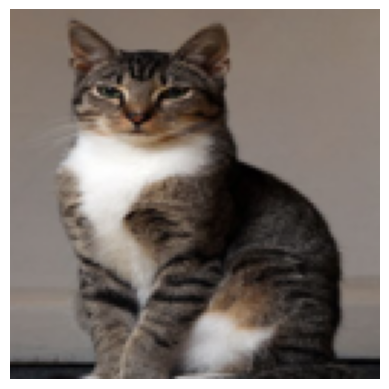

In [23]:
# Get uploaded image name
image_path = list(uploaded.keys())[0]

# Load and resize image
img = Image.open(image_path).convert("RGB")
img = img.resize((128, 128))

# Convert image into array
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)

# Predict using trained CNN model
prediction = model.predict(img_array, verbose=0)[0][0]

# Display image and result
plt.imshow(img)
plt.axis("off")

if prediction >= 0.5:
    print("Prediction: DOG")
    print("Confidence:", round(float(prediction) * 100, 2), "%")
else:
    print("Prediction: CAT")
    print("Confidence:", round((1 - float(prediction)) * 100, 2), "%")

plt.show()